In [1]:
!pip install polars scikit-learn mlflow numpy matplotlib seaborn

In [2]:
import polars as pl
from sklearn.model_selection import cross_validate, train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score, accuracy_score, make_scorer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
import mlflow
import mlflow.sklearn
import numpy as np
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

In [3]:
df_reviews_b2w = pl.read_csv(
    '../data/B2W-Reviews01.csv',
    schema_overrides={"product_id": pl.String, 'overall_rating': pl.Int64}
)
df_reviews_b2w

submission_date,reviewer_id,product_id,product_name,product_brand,site_category_lv1,site_category_lv2,review_title,overall_rating,recommend_to_a_friend,review_text,reviewer_birth_year,reviewer_gender,reviewer_state
str,str,str,str,str,str,str,str,i64,str,str,f64,str,str
"""2018-01-01 00:11:28""","""d0fb1ca69422530334178f5c8624aa…","""132532965""","""Notebook Asus Vivobook Max X54…",null,"""Informática""","""Notebook""","""Bom""",4,"""Yes""","""Estou contente com a compra en…",1958.0,"""F""","""RJ"""
"""2018-01-01 00:13:48""","""014d6dc5a10aed1ff1e6f349fb2b05…","""22562178""","""Copo Acrílico Com Canudo 500ml…",null,"""Utilidades Domésticas""","""Copos, Taças e Canecas""","""Preço imbatível, ótima qualida…",4,"""Yes""","""Por apenas R$1994.20,eu conseg…",1996.0,"""M""","""SC"""
"""2018-01-01 00:26:02""","""44f2c8edd93471926fff601274b8b2…","""113022329""","""Panela de Pressão Elétrica Phi…","""philips walita""","""Eletroportáteis""","""Panela Elétrica""","""ATENDE TODAS AS EXPECTATIVA.""",4,"""Yes""","""SUPERA EM AGILIDADE E PRATICID…",1984.0,"""M""","""SP"""
"""2018-01-01 00:35:54""","""ce741665c1764ab2d77539e18d0e4f…","""113851581""","""Betoneira Columbus - Roma Brin…","""roma jensen""","""Brinquedos""","""Veículos de Brinquedo""","""presente mais que desejado""",4,"""Yes""","""MEU FILHO AMOU! PARECE DE VERD…",1985.0,"""F""","""SP"""
"""2018-01-01 01:00:28""","""7d7b6b18dda804a897359276cef0ca…","""131788803""","""Smart TV LED 43"" LG 43UJ6525 U…","""lg""","""TV e Home Theater""","""TV""","""Sem duvidas, excelente""",5,"""Yes""","""A entrega foi no prazo, as ame…",1994.0,"""M""","""MG"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""2018-05-31 23:30:50""","""15f20e95ff44163f3175aaf67a5ae4…","""17962233""","""Carregador De Pilha Sony + 4 P…",null,"""Câmeras e Filmadoras""","""Acessórios para Câmeras e Film…","""Ótimo produto!""",5,"""Yes""","""Vale muito, estou usando no co…",1988.0,"""M""","""RS"""
"""2018-05-31 23:42:25""","""def7cf9028b0673ab8bca3b1d06e08…","""132631701""","""Mop Giratório Fit + Refil Extr…",null,"""Utilidades Domésticas""","""Material de Limpeza""","""Sensacional""",5,"""Yes""","""Prático e barato, super indico…",1979.0,"""F""","""SP"""
"""2018-05-31 23:44:16""","""7bcbf542f5d7dd9a9a192a6805adba…","""16095859""","""Fita Led 5m Rgb 3528 Siliconad…",null,"""Automotivo""","""Iluminação""","""Ótimo produto""",4,"""Yes""","""Chegou antes do prazo previsto…",1979.0,"""F""","""PR"""


In [4]:
df_reviews_b2w.describe()

statistic,submission_date,reviewer_id,product_id,product_name,product_brand,site_category_lv1,site_category_lv2,review_title,overall_rating,recommend_to_a_friend,review_text,reviewer_birth_year,reviewer_gender,reviewer_state
str,str,str,str,str,str,str,str,str,f64,str,str,f64,str,str
"""count""","""132373""","""132373""","""132373""","""132289""","""40982""","""132367""","""128360""","""132071""",132373.0,"""132355""","""129098""",126389.0,"""128237""","""128382"""
"""null_count""","""0""","""0""","""0""","""84""","""91391""","""6""","""4013""","""302""",0.0,"""18""","""3275""",5984.0,"""4136""","""3991"""
"""mean""",null,null,null,null,null,null,null,null,3.492004,null,null,1977.495898,null,null
"""std""",null,null,null,null,null,null,null,null,1.530289,null,null,21.895265,null,null
"""min""","""2018-01-01 00:11:28""","""00009c77e30f08bbbf96904e89c8ea…","""10003394""","""""Celular Lg B-220 Dual Sim 1.4…","""2brasil""","""Agro, Indústria e Comércio""","""Acabamentos para Motos""","""!""",1.0,"""No""","""!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!…",59.0,"""F""","""AC"""
"""25%""",null,null,null,null,null,null,null,null,2.0,null,null,1969.0,null,null
"""50%""",null,null,null,null,null,null,null,null,4.0,null,null,1980.0,null,null
"""75%""",null,null,null,null,null,null,null,null,5.0,null,null,1987.0,null,null
"""max""","""2018-05-31 23:50:33""","""ffffffad55c06da0a44867a044af6b…","""9999""","""�Leo Elixir De Beleza Unissex …","""zte""","""Áudio""","""Ótica""","""ㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤ…",5.0,"""Yes""","""ㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤㅤ…",2018.0,"""M""","""TO"""


In [5]:
print(df_reviews_b2w.schema)

Schema({'submission_date': String, 'reviewer_id': String, 'product_id': String, 'product_name': String, 'product_brand': String, 'site_category_lv1': String, 'site_category_lv2': String, 'review_title': String, 'overall_rating': Int64, 'recommend_to_a_friend': String, 'review_text': String, 'reviewer_birth_year': Float64, 'reviewer_gender': String, 'reviewer_state': String})


In [6]:
df_reviews_b2w = (
    df_reviews_b2w
    .select(['review_text', 'overall_rating', 'site_category_lv1', 'product_id', 'product_name']) 
    .drop_nulls(subset=['review_text', 'overall_rating'])                                         
    .with_columns(                                                                                
        pl.when(pl.col('overall_rating') <= 2).then(0)
        .when(pl.col('overall_rating') == 3).then(1)
        .otherwise(2)
        .alias('label')
    )
)

In [7]:
print(f'Total de instâncias:{df_reviews_b2w.shape[0]}')

print(f'\nDistribuição de classes:\n{df_reviews_b2w['label'].value_counts(normalize=True) * 100}')

print(f'\nCategoria de produtos:\n{df_reviews_b2w['site_category_lv1'].value_counts().head(5)}')

print(f'\nProdutos com mais avaliações\n{df_reviews_b2w['product_name'].value_counts().head(5)}')

Total de instâncias:129098

Distribuição de classes:
shape: (3, 2)
┌───────┬────────────┐
│ label ┆ proportion │
│ ---   ┆ ---        │
│ f64   ┆ f64        │
╞═══════╪════════════╡
│ 100.0 ┆ 12.401431  │
│ 0.0   ┆ 26.159971  │
│ 200.0 ┆ 61.438597  │
└───────┴────────────┘

Categoria de produtos:
shape: (5, 2)
┌───────────────────────────────┬───────┐
│ site_category_lv1             ┆ count │
│ ---                           ┆ ---   │
│ str                           ┆ u32   │
╞═══════════════════════════════╪═══════╡
│ Alimentos e Bebidas           ┆ 681   │
│ Ar-condicionado e Aquecedores ┆ 751   │
│ Artigos de Festa              ┆ 6     │
│ Artesanato                    ┆ 23    │
│ Agro, Indústria e Comércio    ┆ 269   │
└───────────────────────────────┴───────┘

Produtos com mais avaliações
shape: (5, 2)
┌─────────────────────────────────┬───────┐
│ product_name                    ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════

In [8]:
X = df_reviews_b2w['review_text']
y = df_reviews_b2w['label']

In [9]:
vec = TfidfVectorizer()
vec.fit(X)
vocab_size = len(vec.vocabulary_)
print(f"Total de palavras distintas no corpus: {vocab_size}")

Total de palavras distintas no corpus: 50336


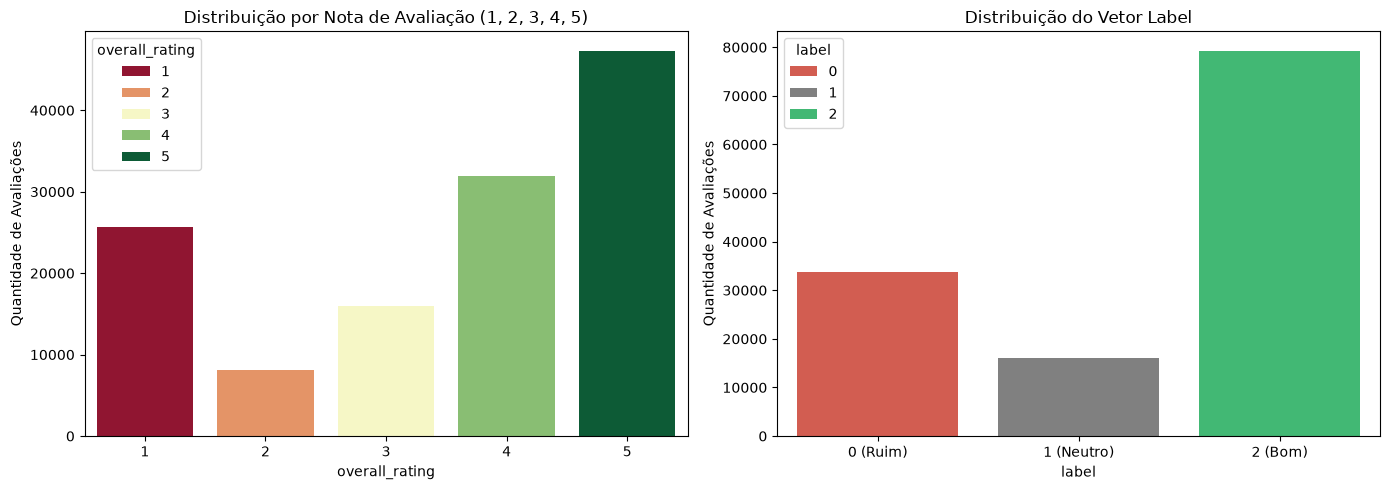

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=df_reviews_b2w,
    x='overall_rating',
    hue='overall_rating',
    palette='RdYlGn',
    ax=axes[0],
)
axes[0].set_title("Distribuição por Nota de Avaliação (1, 2, 3, 4, 5)")
axes[0].set_ylabel("Quantidade de Avaliações")

sns.countplot(
    data=df_reviews_b2w,
    x='label',
    hue='label',
    palette=["#e74c3c", "#808080", "#2ecc71"],
    ax=axes[1],
)
axes[1].set_title("Distribuição do Vetor Label")
axes[1].set_xticks([0, 1, 2])
axes[1].set_xticklabels(['0 (Ruim)', '1 (Neutro)', '2 (Bom)'])
axes[1].set_ylabel("Quantidade de Avaliações")

plt.tight_layout()
plt.show()


In [ ]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive_Bayes": MultinomialNB(),
    "SVM_OvO": SVC(kernel='linear', decision_function_shape='ovo', class_weight='balanced', random_state=42),
    "Decision_Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42)
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("Baseline_B2W_TFIDF")

for model_name, classifier in models.items():

    with mlflow.start_run(run_name=f"{model_name}_B2W"):
        
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

        mlflow.log_param("dataset", "B2W")
        mlflow.log_param("representation", "TF-IDF")
        mlflow.log_param("classifier", model_name)
        mlflow.log_param("max_features", "None")

        pipeline = Pipeline([
            ('tfidf', TfidfVectorizer()),
            ('clf', classifier)
        ])

        scoring_metrics = {
            'accuracy': 'accuracy',
            'precision_macro': make_scorer(precision_score, average='macro', zero_division=0),
            'recall_macro': make_scorer(recall_score, average='macro', zero_division=0),
            'f1_macro': make_scorer(f1_score, average='macro', zero_division=0)
        }

        cv_results = cross_validate(pipeline, X_train, y_train, cv=skf, scoring=scoring_metrics, n_jobs=-1)
        
        mlflow.log_metric("cv_accuracy_mean", np.mean(cv_results['test_accuracy']))
        mlflow.log_metric("cv_precision_mean", np.mean(cv_results['test_precision_macro']))
        mlflow.log_metric("cv_recall_mean", np.mean(cv_results['test_recall_macro']))
        mlflow.log_metric("cv_f1_macro_mean", np.mean(cv_results['test_f1_macro']))
        
        mlflow.log_metric("cv_f1_macro_std", np.std(cv_results['test_f1_macro']))
        mlflow.log_metric("cv_fit_time_mean", np.mean(cv_results['fit_time']))

        pipeline.fit(X_train, y_train)
        
        vocab_size_pipeline = len(pipeline.named_steps['tfidf'].vocabulary_)
        mlflow.log_metric("actual_num_features", vocab_size_pipeline)

        y_pred = pipeline.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
        rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
        f1 = f1_score(y_test, y_pred, average='macro')

        mlflow.log_metric("test_accuracy", acc)
        mlflow.log_metric("test_precision", prec)
        mlflow.log_metric("test_recall", rec)
        mlflow.log_metric("test_f1_score", f1)

        mlflow.sklearn.log_model(
            sk_model=pipeline,
            name="model",
            serialization_format="skops",
            skops_trusted_types=["scipy.sparse._csr.csr_matrix"]
        )


2026/09/22 21:28:57 INFO mlflow.tracking.fluent: Experiment with name 'Baseline_B2W_TFIDF' does not exist. Creating a new experiment.
